In [ ]:

# LYRICLAB AI — STEP 1: ENVIRONMENT SETUP

%pip -q install librosa pretty_midi soundfile



In [ ]:

# LYRICLAB AI — STEP 2: IMPORT LIBRARIES

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import soundfile as sf
import pretty_midi

from IPython.display import Audio, display
from pathlib import Path

# Reproducibility
np.random.seed(42)

# Create folders for our project
PROJECT_DIR = Path("/content/LyricLab")
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"

DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("LyricLab environment is ready!")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Librosa:", librosa.__version__)
print("Project folder:", PROJECT_DIR)


LyricLab environment is ready!
NumPy: 2.1.3
Pandas: 2.2.3
Librosa: 0.11.0
Project folder: /content/LyricLab


In [ ]:

# LYRICLAB AI — STEP 3: USER INPUT

lyrics = """
Walking through the night,
Chasing dreams of light,
Every step I take,
A new path I make.
"""

genre = "rap"       # Try: rap, pop, lo-fi
mood = "energetic"  # Try: energetic, calm, sad

bpm = 100            # Beats per minute

print("Lyrics loaded!")
print("Genre:", genre)
print("Mood:", mood)
print("Tempo:", bpm, "BPM")
print("Number of lyric lines:", len([line for line in lyrics.splitlines() if line.strip()]))


Lyrics loaded!
Genre: rap
Mood: energetic
Tempo: 100 BPM
Number of lyric lines: 4


In [ ]:

# LYRICLAB AI — STEP 4: PROCEDURAL BEAT GENERATOR

import numpy as np
from IPython.display import Audio, display

sample_rate = 22050
seconds_per_beat = 60 / bpm
total_beats = max(16, len([line for line in lyrics.splitlines() if line.strip()]) * 8)
duration = total_beats * seconds_per_beat

audio = np.zeros(int(sample_rate * duration))

def add_tone(start_time, frequency, length, amplitude=0.4):
    start = int(start_time * sample_rate)
    count = min(int(length * sample_rate), len(audio) - start)

    if count <= 0:
        return

    t = np.arange(count) / sample_rate
    envelope = np.exp(-t * 18)
    audio[start:start + count] += amplitude * envelope * np.sin(2 * np.pi * frequency * t)

# Simple kick, snare and hi-hat sounds
for beat in range(total_beats):
    time = beat * seconds_per_beat

    # Kick on beats 1 and 3
    if beat % 4 in [0, 2]:
        add_tone(time, 65, 0.22, 0.8)

    # Snare on beats 2 and 4
    if beat % 4 in [1, 3]:
        add_tone(time, 180, 0.12, 0.35)

    # Hi-hat on every half-beat
    for offset in [0, 0.5]:
        hat_time = time + offset * seconds_per_beat
        add_tone(hat_time, 7000, 0.025, 0.08)

# Prevent clipping
audio = audio / (np.max(np.abs(audio)) + 1e-9) * 0.9

print(f"Generated {duration:.1f} seconds of original procedural audio.")
display(Audio(audio, rate=sample_rate))


Generated 19.2 seconds of original procedural audio.


In [ ]:

# LYRICLAB AI — STEP 5: LYRIC-AWARE RAP RHYTHM

import numpy as np
from IPython.display import Audio, display

def count_syllables(word):
    """Estimate syllables using vowel groups; this is a simple heuristic."""
    word = ''.join(c for c in word.lower() if c.isalpha())
    if not word:
        return 0

    vowels = "aeiouy"
    count = 0
    previous_vowel = False

    for char in word:
        is_vowel = char in vowels
        if is_vowel and not previous_vowel:
            count += 1
        previous_vowel = is_vowel

    # Basic correction for a silent 'e'
    if word.endswith("e") and count > 1 and not word.endswith(("le", "ye")):
        count -= 1

    return max(1, count)

# Analyse each lyric line
lines = [line.strip() for line in lyrics.splitlines() if line.strip()]
line_syllables = []

for line in lines:
    words = line.split()
    syllables = sum(count_syllables(word) for word in words)
    line_syllables.append(syllables)
    print(f"{line}  |  Estimated syllables: {syllables}")

# Create a new audio track
sample_rate = 22050
seconds_per_beat = 60 / bpm
beats_per_line = 4
total_beats = max(16, len(lines) * beats_per_line)
audio = np.zeros(int(total_beats * seconds_per_beat * sample_rate))

def add_sound(start_time, frequency, length, amplitude=0.3):
    start = int(start_time * sample_rate)
    count = min(int(length * sample_rate), len(audio) - start)

    if count <= 0:
        return

    t = np.arange(count) / sample_rate
    envelope = np.exp(-t * 22)
    audio[start:start + count] += (
        amplitude * envelope * np.sin(2 * np.pi * frequency * t)
    )

# Build the beat and place a marker for every estimated syllable
for line_index, syllable_count in enumerate(line_syllables):
    line_start_beat = line_index * beats_per_line
    line_duration = beats_per_line * seconds_per_beat

    # Spread syllable markers evenly across each line
    for i in range(syllable_count):
        position = (i / max(1, syllable_count)) * line_duration
        marker_time = line_start_beat * seconds_per_beat + position

        # Higher-pitched marker = estimated syllable timing
        add_sound(marker_time, 1100, 0.045, 0.13)

# Add kick, snare and hi-hat percussion
for beat in range(total_beats):
    time = beat * seconds_per_beat

    if beat % 4 in [0, 2]:
        add_sound(time, 65, 0.20, 0.65)

    if beat % 4 in [1, 3]:
        add_sound(time, 180, 0.10, 0.30)

    for offset in [0, 0.5]:
        add_sound(time + offset * seconds_per_beat, 7000, 0.025, 0.06)

# Normalise audio
audio = audio / (np.max(np.abs(audio)) + 1e-9) * 0.9

print("\nLyric-aware rhythm generated!")
print("Lines analysed:", len(lines))
print("Estimated total syllables:", sum(line_syllables))
display(Audio(audio, rate=sample_rate))


Walking through the night,  |  Estimated syllables: 5
Chasing dreams of light,  |  Estimated syllables: 5
Every step I take,  |  Estimated syllables: 6
A new path I make.  |  Estimated syllables: 5

Lyric-aware rhythm generated!
Lines analysed: 4
Estimated total syllables: 21


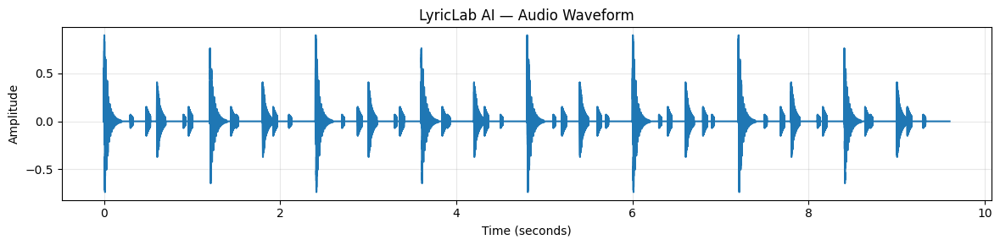

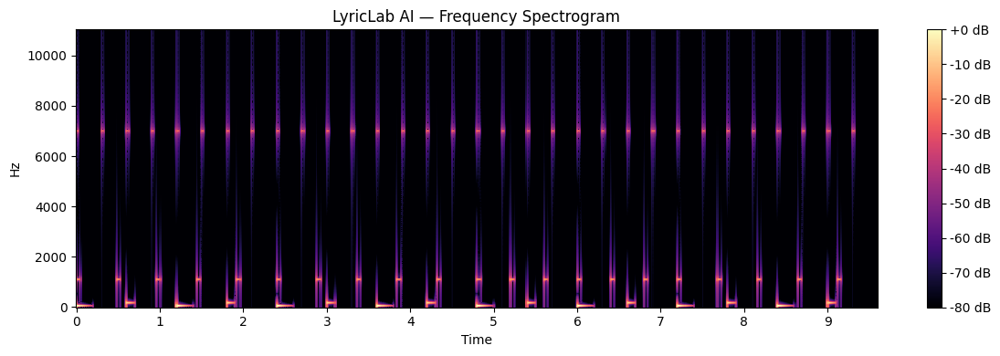

Waveform and spectrogram generated successfully!


In [ ]:

# LYRICLAB AI — STEP 6: AUDIO TIME-SERIES ANALYSIS

import numpy as np
import matplotlib.pyplot as plt
import librosa
import librosa.display

# Use the audio generated in Step 5
time_axis = np.arange(len(audio)) / sample_rate

# 1. WAVEFORM: amplitude over time
plt.figure(figsize=(12, 3))
plt.plot(time_axis, audio)
plt.title("LyricLab AI — Audio Waveform")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 2. SPECTROGRAM: frequencies over time
D = librosa.stft(audio, n_fft=1024, hop_length=256)
D_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)

plt.figure(figsize=(12, 4))
librosa.display.specshow(
    D_db,
    sr=sample_rate,
    hop_length=256,
    x_axis="time",
    y_axis="hz",
    cmap="magma"
)
plt.colorbar(format="%+2.0f dB")
plt.title("LyricLab AI — Frequency Spectrogram")
plt.tight_layout()
plt.show()

print("Waveform and spectrogram generated successfully!")


In [ ]:

# LYRICLAB AI — STEP 7: FEATURE EXTRACTION

# Root-mean-square energy: loudness variation over time
rms = librosa.feature.rms(y=audio, frame_length=1024, hop_length=256)[0]

# Spectral centroid: approximate brightness of the sound
centroid = librosa.feature.spectral_centroid(
    y=audio, sr=sample_rate, n_fft=1024, hop_length=256
)[0]

# Zero-crossing rate: how often the signal crosses zero
zcr = librosa.feature.zero_crossing_rate(
    audio, frame_length=1024, hop_length=256
)[0]

# Convert frames into timestamps
timestamps = librosa.frames_to_time(
    np.arange(len(rms)), sr=sample_rate, hop_length=256
)

# Store the features in a table
min_length = min(len(timestamps), len(centroid), len(zcr))

features = pd.DataFrame({
    "time_seconds": timestamps[:min_length],
    "rms_energy": rms[:min_length],
    "spectral_centroid": centroid[:min_length],
    "zero_crossing_rate": zcr[:min_length]
})

display(features.head(10))

print("\nAverage RMS energy:", round(float(features["rms_energy"].mean()), 4))
print("Average spectral centroid:", round(float(features["spectral_centroid"].mean()), 2), "Hz")
print("Average zero-crossing rate:", round(float(features["zero_crossing_rate"].mean()), 4))


,time_seconds,rms_energy,spectral_centroid,zero_crossing_rate
0,0.00000,0.309255,1226.052909,0.015625
1,0.01161,0.342811,1018.269499,0.017578
2,0.02322,0.360496,1262.146352,0.021484
3,0.03483,0.279441,946.690393,0.015625
4,0.04644,0.215146,463.545782,0.007812
5,0.05805,0.165094,273.938378,0.007812
6,0.06966,0.127690,65.044043,0.005859
7,0.08127,0.098078,65.795971,0.005859
8,0.09288,0.076848,65.044869,0.005859
9,0.10449,0.058664,65.820832,0.005859



Average RMS energy: 0.0435
Average spectral centroid: 1208.78 Hz
Average zero-crossing rate: 0.0378


In [ ]:

# LYRICLAB AI — STEP 8: MELODY AND BASS GENERATOR

import numpy as np
from IPython.display import Audio, display

# Musical scales (note names represented as MIDI numbers)
scales = {
    "energetic": [60, 62, 64, 67, 69, 72],  # C major pentatonic
    "calm":      [60, 62, 64, 67, 69, 72],
    "sad":       [60, 62, 63, 65, 67, 70]   # C minor pentatonic
}

scale = scales.get(mood.lower(), scales["energetic"])

# Start with the beat from Step 5
music = audio.copy()
beat_duration = 60 / bpm

def add_note(track, start_time, frequency, duration, volume=0.2):
    start = int(start_time * sample_rate)
    length = int(duration * sample_rate)
    end = min(start + length, len(track))

    if start >= len(track) or end <= start:
        return

    t = np.arange(end - start) / sample_rate

    # Soft plucked sound with a decaying envelope
    envelope = np.exp(-5 * t / max(duration, 0.01))
    tone = (
        np.sin(2 * np.pi * frequency * t)
        + 0.3 * np.sin(4 * np.pi * frequency * t)
    )
    track[start:end] += volume * envelope * tone

# Generate melody notes
rng = np.random.default_rng(42)
melody_choices = scale + [n + 12 for n in scale]

for beat in range(int(len(music) / sample_rate / beat_duration)):
    # Leave some spaces to make the melody less repetitive
    if rng.random() < 0.75:
        midi_note = int(rng.choice(melody_choices))
        frequency = 440 * (2 ** ((midi_note - 69) / 12))

        add_note(
            music,
            beat * beat_duration,
            frequency,
            duration=beat_duration * 0.75,
            volume=0.15
        )

# Generate a bassline, following a simple four-beat pattern
bass_notes = [36, 36, 43, 36] if mood.lower() != "sad" else [36, 36, 41, 36]

for beat in range(int(len(music) / sample_rate / beat_duration)):
    midi_note = bass_notes[beat % len(bass_notes)]
    frequency = 440 * (2 ** ((midi_note - 69) / 12))

    add_note(
        music,
        beat * beat_duration,
        frequency,
        duration=beat_duration * 0.85,
        volume=0.22
    )

# Normalise the combined track
music = music / (np.max(np.abs(music)) + 1e-9) * 0.9

print("Melody + bassline + beat generated!")
display(Audio(music, rate=sample_rate))


Melody + bassline + beat generated!


In [ ]:

# LYRICLAB AI — STEP 9: COMPARE THE TWO TRACKS

def get_audio_summary(signal, label):
    rms_values = librosa.feature.rms(y=signal)[0]
    centroid_values = librosa.feature.spectral_centroid(
        y=signal, sr=sample_rate
    )[0]

    return {
        "Track": label,
        "Duration (seconds)": round(len(signal) / sample_rate, 2),
        "Mean RMS energy": round(float(np.mean(rms_values)), 4),
        "Mean spectral centroid (Hz)": round(float(np.mean(centroid_values)), 2)
    }

comparison = pd.DataFrame([
    get_audio_summary(audio, "Original beat"),
    get_audio_summary(music, "Beat + melody + bass")
])

display(comparison)


,Track,Duration (seconds),Mean RMS energy,Mean spectral centroid (Hz)
0,Original beat,9.6,0.0504,1750.48
1,Beat + melody + bass,9.6,0.0507,1464.34


Training samples: 657
Testing samples: 165
Random Forest MAE: 0.00466
Random Forest RMSE: 0.01538
Baseline MAE: 0.00879


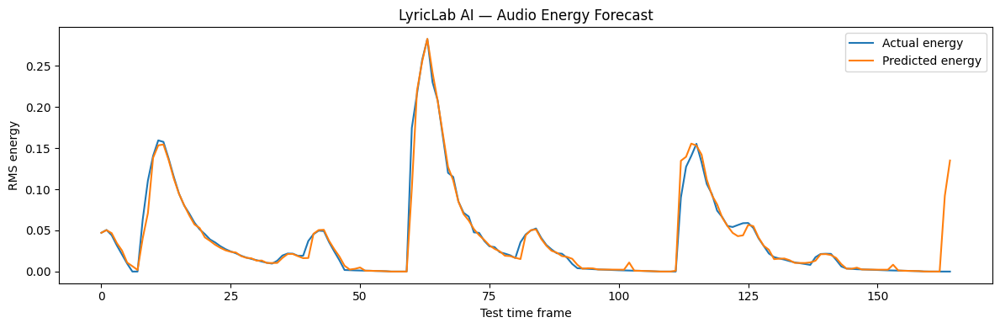

In [ ]:

# LYRICLAB AI — STEP 10: TIME-SERIES ML MODEL

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Extract energy over time from the generated composition
energy = librosa.feature.rms(
    y=music, frame_length=1024, hop_length=256
)[0]

# Create a dataset: previous 5 energy values predict the next one
lags = 5
X, y = [], []

for i in range(lags, len(energy)):
    X.append(energy[i-lags:i])
    y.append(energy[i])

X = np.array(X)
y = np.array(y)

# Keep chronological order: first 80% for training, last 20% for testing
split = int(len(X) * 0.8)
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# Train the model
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    max_depth=8
)
model.fit(X_train, y_train)

# Predict future energy
predictions = model.predict(X_test)

# Compare with a simple baseline: predict energy stays at its last value
baseline = X_test[:, -1]

# Evaluate predictions
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))

baseline_mae = mean_absolute_error(y_test, baseline)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Random Forest MAE:", round(mae, 5))
print("Random Forest RMSE:", round(rmse, 5))
print("Baseline MAE:", round(baseline_mae, 5))

# Plot actual versus predicted energy
plt.figure(figsize=(12, 4))
plt.plot(y_test[:200], label="Actual energy")
plt.plot(predictions[:200], label="Predicted energy")
plt.title("LyricLab AI — Audio Energy Forecast")
plt.xlabel("Test time frame")
plt.ylabel("RMS energy")
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:

# LYRICLAB AI — STEP 11: LYRIC-TO-MELODY COMPOSITION

import numpy as np
from IPython.display import Audio, display

# Get the lyrics entered in Step 3
lines = [line.strip() for line in lyrics.splitlines() if line.strip()]

# Estimate syllables using our earlier function
syllable_counts = [sum(count_syllables(w) for w in line.split())
                   for line in lines]

# Musical scales for different moods
scales = {
    "energetic": [60, 62, 64, 67, 69, 72],
    "calm":      [60, 62, 64, 67, 69, 72],
    "sad":       [60, 62, 63, 65, 67, 70]
}
scale = scales.get(mood.lower(), scales["energetic"])

# Create a melody track matching the instrumental length
lyric_melody = np.zeros(len(music))
rng = np.random.default_rng(21)

def add_melody_note(start_time, midi_note, duration, volume=0.18):
    start = int(start_time * sample_rate)
    length = int(duration * sample_rate)
    end = min(start + length, len(lyric_melody))

    if start >= len(lyric_melody) or end <= start:
        return

    t = np.arange(end - start) / sample_rate
    envelope = np.exp(-3.5 * t / max(duration, 0.01))

    frequency = 440 * (2 ** ((midi_note - 69) / 12))
    tone = (
        np.sin(2 * np.pi * frequency * t)
        + 0.25 * np.sin(2 * np.pi * frequency * 2 * t)
    )

    lyric_melody[start:end] += volume * envelope * tone

# Each lyric line occupies four beats
seconds_per_beat = 60 / bpm
line_duration = 4 * seconds_per_beat

for line_index, syllables in enumerate(syllable_counts):
    if syllables == 0:
        continue

    line_start = line_index * line_duration

    # One note per estimated syllable
    for syllable_index in range(syllables):
        note_position = syllable_index / syllables
        start_time = line_start + note_position * line_duration

        # Choose notes from the selected musical scale
        note = int(rng.choice(scale))

        # Give the last syllable a more resolved ending
        if syllable_index == syllables - 1:
            note = scale[0] + 12

        note_length = min(
            line_duration / syllables * 0.8,
            0.35
        )

        add_melody_note(start_time, note, note_length)

# Combine melody and existing instrumental
composition = music + lyric_melody
composition = composition / (np.max(np.abs(composition)) + 1e-9) * 0.9

print("Composition created!")
print("Lyric lines:", len(lines))
print("Estimated syllables:", sum(syllable_counts))
print("Mood:", mood, "| Tempo:", bpm, "BPM")
display(Audio(composition, rate=sample_rate))


Composition created!
Lyric lines: 4
Estimated syllables: 21
Mood: energetic | Tempo: 100 BPM


STYLE: TRAP
MOOD: CONFIDENT
TEMPO: 100 BPM
LYRIC LINES: 4
ESTIMATED SYLLABLES: 26

Your trap instrumental is ready!
Duration: 57.6 seconds


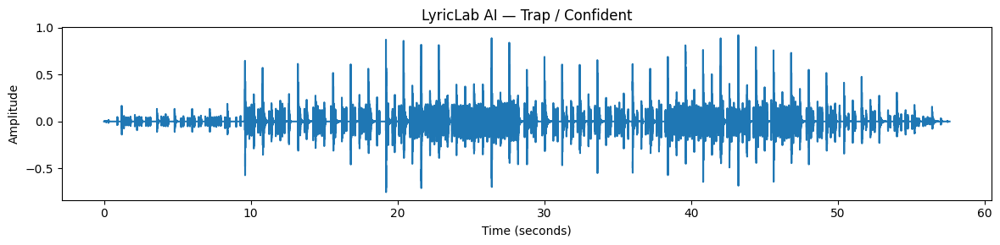

In [ ]:

# LYRICLAB AI — STEP 12: STYLE-AWARE MUSIC GENERATOR
# Generates an original instrumental arrangement from lyric input.

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, display

# =====================================================
# 1. USER INPUT — CHANGE THESE FOR EACH NEW SONG
# =====================================================

song_lyrics = """
Running through the fire,
Taking dreams up higher,
Every fall makes me strong,
Now I know where I belong.
"""

style = "trap"       # rap, trap, pop, lofi, cinematic
mood = "confident"   # confident, happy, sad, calm, intense
tempo = 100          # BPM: try 80–140

# =====================================================
# 2. STYLE CONFIGURATION
# =====================================================

styles = {
    "rap": {
        "bpm": 95, "scale": [60, 62, 64, 67, 69],
        "kick": 0.75, "hat": 0.15, "bass": 0.25
    },
    "trap": {
        "bpm": 140, "scale": [60, 63, 65, 67, 70],
        "kick": 0.85, "hat": 0.12, "bass": 0.35
    },
    "pop": {
        "bpm": 110, "scale": [60, 62, 64, 67, 69],
        "kick": 0.65, "hat": 0.10, "bass": 0.20
    },
    "lofi": {
        "bpm": 80, "scale": [60, 62, 63, 67, 70],
        "kick": 0.45, "hat": 0.07, "bass": 0.18
    },
    "cinematic": {
        "bpm": 100, "scale": [60, 62, 65, 67, 72],
        "kick": 0.65, "hat": 0.06, "bass": 0.25
    }
}

config = styles.get(style.lower(), styles["rap"])
bpm = tempo if tempo else config["bpm"]
scale = config["scale"]

# Mood changes the arrangement's intensity
intensity = {
    "confident": 1.0,
    "happy": 0.85,
    "sad": 0.55,
    "calm": 0.45,
    "intense": 1.2
}.get(mood.lower(), 1.0)

# =====================================================
# 3. LYRIC ANALYSIS
# =====================================================

lines = [line.strip() for line in song_lyrics.splitlines()
         if line.strip()]

def estimate_syllables(word):
    word = ''.join(c for c in word.lower() if c.isalpha())
    count = 0
    previous = False

    for char in word:
        vowel = char in "aeiouy"
        if vowel and not previous:
            count += 1
        previous = vowel

    if word.endswith("e") and count > 1 and not word.endswith(("le", "ye")):
        count -= 1

    return max(1, count) if word else 0

syllables = [
    sum(estimate_syllables(word) for word in line.split())
    for line in lines
]

print("STYLE:", style.upper())
print("MOOD:", mood.upper())
print("TEMPO:", bpm, "BPM")
print("LYRIC LINES:", len(lines))
print("ESTIMATED SYLLABLES:", sum(syllables))

# =====================================================
# 4. SONG STRUCTURE
# Intro → Verse → Hook → Verse → Hook → Outro
# =====================================================

sample_rate = 22050
beat_duration = 60 / bpm
beats_per_bar = 4

# Each lyric line gets one bar, with at least 8 bars total
verse_bars = max(4, len(lines))
section_bars = [
    ("Intro", 4),
    ("Verse", verse_bars),
    ("Hook / Drop", 4),
    ("Verse 2", verse_bars),
    ("Final Hook", 4),
    ("Outro", 4)
]

sections = []
current_bar = 0

for name, bars in section_bars:
    sections.append((name, current_bar, current_bar + bars))
    current_bar += bars

total_beats = current_bar * beats_per_bar
duration = total_beats * beat_duration
audio = np.zeros(int(duration * sample_rate))
rng = np.random.default_rng()

# =====================================================
# 5. SOUND ENGINE
# =====================================================

def add_tone(time, frequency, length, volume, harmonics=False):
    start = int(time * sample_rate)
    count = min(int(length * sample_rate), len(audio) - start)

    if count <= 0 or start >= len(audio):
        return

    t = np.arange(count) / sample_rate
    envelope = np.exp(-5 * t / max(length, 0.01))

    wave = np.sin(2 * np.pi * frequency * t)

    if harmonics:
        wave += 0.25 * np.sin(4 * np.pi * frequency * t)

    audio[start:start + count] += volume * envelope * wave

def add_noise(time, length, volume):
    start = int(time * sample_rate)
    count = min(int(length * sample_rate), len(audio) - start)

    if count <= 0 or start >= len(audio):
        return

    noise = rng.normal(0, 1, count)
    envelope = np.exp(-35 * np.arange(count) / sample_rate)
    audio[start:start + count] += volume * noise * envelope

# =====================================================
# 6. DYNAMIC DRUMS, BASS AND MELODY
# =====================================================

for beat in range(total_beats):
    t = beat * beat_duration
    bar = beat // beats_per_bar
    beat_in_bar = beat % beats_per_bar

    section = next(
        name for name, start, end in sections
        if start * 4 <= beat < end * 4
    )

    # Arrangement intensity varies by section
    level = 0.35 if section == "Intro" else 1.0
    if section in ["Hook / Drop", "Final Hook"]:
        level = 1.25
    if section == "Outro":
        level = max(0.15, 1 - (bar - sections[-1][1]) / 4)

    # Kick drum
    if beat_in_bar in [0, 2]:
        if rng.random() < 0.92:
            add_tone(t, 58, 0.22, config["kick"] * intensity * level)

    # Snare / clap
    if beat_in_bar in [1, 3] and section != "Intro":
        add_noise(t, 0.12, 0.18 * intensity * level)

    # Hi-hats: faster in trap and hook sections
    subdivisions = 4 if style.lower() == "trap" else 2
    for sub in range(subdivisions):
        hat_time = t + sub * beat_duration / subdivisions
        if rng.random() < (0.8 if section in
                           ["Hook / Drop", "Final Hook"] else 0.55):
            add_noise(hat_time, 0.025, config["hat"] * level)

    # Bass notes on the beat
    if beat_in_bar in [0, 2] and section != "Intro":
        bass_note = 36 if beat_in_bar == 0 else 43
        bass_freq = 440 * 2 ** ((bass_note - 69) / 12)
        add_tone(t, bass_freq, beat_duration * 0.85,
                 config["bass"] * intensity * level)

    # Melody: different notes and density by section
    if section in ["Verse", "Verse 2", "Hook / Drop", "Final Hook"]:
        probability = 0.8 if "Hook" in section else 0.45

        if rng.random() < probability:
            note = int(rng.choice(scale))
            if "Hook" in section:
                note += 12

            frequency = 440 * 2 ** ((note - 69) / 12)
            add_tone(t, frequency, beat_duration * 0.65,
                     0.13 * intensity * level, harmonics=True)

# Smooth fade at the beginning and end
fade_length = min(int(sample_rate * 1.0), len(audio) // 2)
audio[:fade_length] *= np.linspace(0, 1, fade_length)
audio[-fade_length:] *= np.linspace(1, 0, fade_length)

# Prevent clipping
audio = audio / (np.max(np.abs(audio)) + 1e-9) * 0.92

print(f"\nYour {style} instrumental is ready!")
print(f"Duration: {duration:.1f} seconds")
display(Audio(audio, rate=sample_rate))

# =====================================================
# 7. VISUALISE SONG ENERGY
# =====================================================

plt.figure(figsize=(12, 3))
plt.plot(np.arange(len(audio)) / sample_rate, audio)
plt.title(f"LyricLab AI — {style.title()} / {mood.title()}")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.tight_layout()
plt.show()


In [ ]:

%pip -q install gTTS


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
huggingface-hub 1.33.0 requires click<9.0.0,>=8.4.2, but you have click 8.1.8 which is incompatible.
wandb 0.28.1 requires click>=8.2.0, but you have click 8.1.8 which is incompatible.
spacy 3.8.16 requires click<9.0.0,>=8.2.1, but you have click 8.1.8 which is incompatible.


In [ ]:

import gtts
print("gTTS installed successfully!")
print("Version:", gtts.__version__)


gTTS installed successfully!
Version: 2.5.4


In [ ]:

from gtts import gTTS
from IPython.display import Audio, display
import librosa
import tempfile
import os

text = "Walking through the night, chasing dreams of light."

with tempfile.NamedTemporaryFile(suffix=".mp3", delete=False) as f:
    path = f.name

try:
    gTTS(text=text, lang="en").save(path)
    voice, sr = librosa.load(path, sr=22050)
    display(Audio(voice, rate=sr))
    print("Voice test successful!")
finally:
    if os.path.exists(path):
        os.remove(path)


Voice test successful!


In [ ]:

# LYRICLAB AI — STEP 14: THREE SONG VERSIONS

from gtts import gTTS
from IPython.display import Audio, display
import librosa
import numpy as np
import tempfile
import os
import pandas as pd

# Use the lyrics entered earlier
lyrics_text = "\n".join(
    line.strip()
    for line in song_lyrics.splitlines()
    if line.strip()
)

# Generate speech once
with tempfile.NamedTemporaryFile(suffix=".mp3", delete=False) as f:
    voice_path = f.name

try:
    gTTS(text=lyrics_text, lang="en", slow=False).save(voice_path)
    voice, _ = librosa.load(voice_path, sr=sample_rate, mono=True)
finally:
    if os.path.exists(voice_path):
        os.remove(voice_path)

# Create three mixes with different vocal levels and intro lengths
versions = [
    {"name": "Version A — Vocal Forward", "vocal_level": 0.90, "intro_seconds": 1.0},
    {"name": "Version B — Balanced",      "vocal_level": 0.65, "intro_seconds": 2.0},
    {"name": "Version C — Instrumental Forward", "vocal_level": 0.40, "intro_seconds": 3.0},
]

song_versions = []
report = []

for version in versions:
    start = int(version["intro_seconds"] * sample_rate)
    total_length = max(len(music), start + len(voice))

    backing = np.zeros(total_length)
    backing[:len(music)] = music

    mix = backing.copy()
    mix[start:start + len(voice)] += version["vocal_level"] * voice

    mix = mix / (np.max(np.abs(mix)) + 1e-9) * 0.92
    song_versions.append(mix)

    report.append({
        "Version": version["name"],
        "Vocal level": version["vocal_level"],
        "Intro (seconds)": version["intro_seconds"],
        "Duration (seconds)": round(len(mix) / sample_rate, 2)
    })

display(pd.DataFrame(report))

for version, mix in zip(versions, song_versions):
    print("\n", version["name"])
    display(Audio(mix, rate=sample_rate))


,Version,Vocal level,Intro (seconds),Duration (seconds)
0,Version A — Vocal Forward,0.90,1.0,9.60
1,Version B — Balanced,0.65,2.0,10.14
2,Version C — Instrumental Forward,0.40,3.0,11.14



 Version A — Vocal Forward



 Version B — Balanced



 Version C — Instrumental Forward


In [ ]:

# LYRICLAB AI — STEP 16: CHECK GPU

import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected. Enable a GPU under Runtime settings.")


PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [ ]:

# LYRICLAB AI — STEP 17: INSTALL MUSIC MODEL DEPENDENCIES

%pip -q install -U diffusers transformers accelerate safetensors soundfile


In [ ]:

# LYRICLAB AI — STEP 18: LOAD ACE-STEP 1.5

import torch
import soundfile as sf
import numpy as np
from IPython.display import Audio, display
from diffusers import AceStepPipeline

if not torch.cuda.is_available():
    raise RuntimeError(
        "A GPU is required for this first test. "
        "Enable GPU under Runtime > Change runtime type."
    )

model_id = "ACE-Step/acestep-v15-xl-turbo-diffusers"

dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16

pipe = AceStepPipeline.from_pretrained(
    model_id,
    torch_dtype=dtype
)

pipe = pipe.to("cuda")

print("ACE-Step pipeline loaded successfully!")
print("Sample rate:", pipe.sample_rate)


/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/491 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 19 files:   0%|          | 0/19 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

ACE-Step pipeline loaded successfully!
Sample rate: 48000


In [ ]:

# LYRICLAB AI — STEP 19: FIRST PRETRAINED MUSIC GENERATION

lyrics_input = """
[Verse]
I rise again, I own my name
I walk through fire, I welcome change

[Chorus]
I am fearless, I stand tall
I keep on rising through it all
"""

music_prompt = (
    "Confident female rap vocals in English, medium-tempo hip-hop, "
    "punchy modern drums, deep bass, catchy melodic hook, "
    "polished studio production, dynamic verse and chorus."
)

result = pipe(
    prompt=music_prompt,
    lyrics=lyrics_input,
    audio_duration=30.0,
    vocal_language="en",
    num_inference_steps=8,
    shift=3.0,
)

generated_audio = result.audios[0].T.cpu().float().numpy()

sf.write(
    "/content/LyricLab_AI_test.wav",
    generated_audio,
    pipe.sample_rate
)

print("Generated audio shape:", generated_audio.shape)
display(Audio(generated_audio, rate=pipe.sample_rate))


Guidance scale 7.0 is ignored for turbo (guidance-distilled) checkpoints.


  0%|          | 0/8 [00:00<?, ?it/s]

OutOfMemoryError: CUDA out of memory. Tried to allocate 2.40 GiB. GPU 0 has a total capacity of 14.56 GiB of which 2.04 GiB is free. Including non-PyTorch memory, this process has 12.52 GiB memory in use. Of the allocated memory 11.75 GiB is allocated by PyTorch, and 664.57 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)

In [ ]:
import gc
import torch

gc.collect()
torch.cuda.empty_cache()

print(f"GPU memory free: {torch.cuda.mem_get_info()[0] / 1024**3:.2f} GiB")

GPU memory free: 2.04 GiB


In [ ]:
# Enable memory-efficient attention if supported
try:
    pipe.enable_attention_slicing()
    print("Attention slicing enabled.")
except Exception as e:
    print("Attention slicing unavailable:", e)

# Move model components between GPU and CPU as needed
pipe.enable_model_cpu_offload()

print("CPU offloading enabled.")

Attention slicing enabled.


In [ ]:
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GiB")

import psutil
print("Available system RAM:", round(
    psutil.virtual_memory().available / 1024**3, 2
), "GiB")

GPU available: True
GPU: Tesla T4
GPU memory: 14.56 GiB
Available system RAM: 9.46 GiB


In [ ]:
%pip -q install -U diffusers transformers accelerate safetensors soundfile

In [ ]:
import torch
import gc
import soundfile as sf
from IPython.display import Audio, display
from diffusers import AceStepPipeline

gc.collect()
torch.cuda.empty_cache()

model_id = "ACE-Step/acestep-v15-xl-turbo-diffusers"
dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16

pipe = AceStepPipeline.from_pretrained(
    model_id,
    dtype=dtype,
    low_cpu_mem_usage=True
)

pipe.enable_model_cpu_offload()
pipe.enable_attention_slicing()

print("Model loaded with CPU offloading.")

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Model loaded with CPU offloading.


In [ ]:
music_prompt = (
    "Female rap vocals in English, medium-tempo hip-hop, "
    "punchy drums, deep bass, confident mood, polished production."
)

lyrics_input = """
[verse]
I rise again, I own my name
I walk through fire, I welcome change

[chorus]
I am fearless, I stand tall
I keep on rising through it all
"""

gc.collect()
torch.cuda.empty_cache()

with torch.inference_mode():
    result = pipe(
        prompt=music_prompt,
        lyrics=lyrics_input,
        audio_duration=10.0,
        vocal_language="en",
        num_inference_steps=8,
        shift=3.0,
    )

generated_audio = result.audios[0].T.cpu().float().numpy()

sf.write(
    "/content/LyricLab_AI_test.wav",
    generated_audio,
    pipe.sample_rate
)

display(Audio(generated_audio, rate=pipe.sample_rate))
print("Song saved successfully!")

Guidance scale 7.0 is ignored for turbo (guidance-distilled) checkpoints.


  0%|          | 0/8 [00:00<?, ?it/s]

In [ ]:
import os
from IPython.display import Audio, display
import soundfile as sf

file_path = "/content/LyricLab_AI_test.wav"

if os.path.exists(file_path):
    audio_data, sample_rate = sf.read(file_path)
    print("✅ Audio file exists!")
    print("Duration:", round(len(audio_data) / sample_rate, 2), "seconds")
    print("Sample rate:", sample_rate)
    display(Audio(audio_data.T if audio_data.ndim > 1 else audio_data,
                  rate=sample_rate))
else:
    print("Audio file not found. The previous cell may not have finished.")

Audio file not found. The previous cell may not have finished.


In [ ]:
import os

print("Runtime files:")
print(os.listdir("/content")[:50])

print("\nAudio files:")
for root, dirs, files_list in os.walk("/content"):
    for name in files_list:
        if name.endswith((".wav", ".mp3", ".flac")):
            print(os.path.join(root, name))

Runtime files:
['.config', 'sample_data']

Audio files:


In [ ]:
print("Has result:", "result" in globals())
print("Has generated_audio:", "generated_audio" in globals())

if "generated_audio" in globals():
    print("Audio shape:", generated_audio.shape)
    print("Sample rate:", pipe.sample_rate)

Has result: False
Has generated_audio: False


In [ ]:
print("Model loaded:", "pipe" in globals())
print("GPU available:", torch.cuda.is_available())

Model loaded: False


NameError: name 'torch' is not defined

In [ ]:
%pip -q install -U diffusers transformers accelerate safetensors soundfile

In [ ]:
import torch
import gc
import soundfile as sf
from IPython.display import Audio, display
from diffusers import AceStepPipeline

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
else:
    raise RuntimeError("Enable GPU: Runtime → Change runtime type → T4 GPU")

model_id = "ACE-Step/acestep-v15-xl-turbo-diffusers"
dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16

pipe = AceStepPipeline.from_pretrained(
    model_id,
    dtype=dtype,
    low_cpu_mem_usage=True
)

pipe.enable_model_cpu_offload()
pipe.enable_attention_slicing()

print("Model loaded successfully!")

model_index.json:   0%|          | 0.00/491 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 19 files:   0%|          | 0/19 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Model loaded successfully!


In [ ]:
import gc
import torch
import soundfile as sf
from google.colab import files

music_prompt = (
    "Confident female rap vocals in English, medium-tempo hip-hop, "
    "punchy drums, deep bass, catchy hook, polished studio production."
)

lyrics_input = """
[verse]
I rise again, I own my name
I walk through fire, I welcome change

[chorus]
I am fearless, I stand tall
I keep on rising through it all
"""

gc.collect()
torch.cuda.empty_cache()

result = pipe(
    prompt=music_prompt,
    lyrics=lyrics_input,
    audio_duration=10.0,
    vocal_language="en",
    num_inference_steps=8,
    shift=3.0,
)

# Save immediately
audio = result.audios[0].T.cpu().float().numpy()
output_path = "/content/LyricLab_AI_test.wav"

sf.write(output_path, audio, pipe.sample_rate)

print("Audio saved:", output_path)
print("Duration:", round(len(audio) / pipe.sample_rate, 2), "seconds")
print("Sample rate:", pipe.sample_rate)

Guidance scale 7.0 is ignored for turbo (guidance-distilled) checkpoints.


  0%|          | 0/8 [00:00<?, ?it/s]

In [ ]:

import sys
import torch

print("Python:", sys.version)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")
print("CUDA available:", torch.cuda.is_available())


Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
GPU: Tesla T4
CUDA available: True


In [ ]:

%pip install -q -U diffusers transformers accelerate safetensors soundfile librosa matplotlib gradio


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.


In [ ]:

import torch
import diffusers
import soundfile
import matplotlib
import gradio

print("All imports successful!")
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")
print("Diffusers:", diffusers.__version__)


All imports successful!
GPU: Tesla T4
Diffusers: 0.42.1


In [ ]:

import gc
import torch
from diffusers import AceStepPipeline

gc.collect()
torch.cuda.empty_cache()

model_id = "ACE-Step/acestep-v15-base"

pipe = AceStepPipeline.from_pretrained(
    model_id,
    dtype=torch.float16,
    low_cpu_mem_usage=True
)

pipe.enable_model_cpu_offload()
pipe.enable_attention_slicing()

print("LyricLab music model loaded!")


RemoteEntryNotFoundError: 404 Client Error. (Request ID: Root=1-6ae31734-018ac7ec0bf2de6d1b7bf2d3;de9b9fe3-43a6-4337-ba65-e20a6fced288)

Entry Not Found for url: https://huggingface.co/ACE-Step/acestep-v15-base/resolve/e432212fec32b8965a14ffa57ae653438d6abd14/model_index.json.

In [ ]:

import gc
import torch
from diffusers import AceStepPipeline

gc.collect()
torch.cuda.empty_cache()

pipe = AceStepPipeline.from_pretrained(
    "Runware/acestep-v15-turbo-diffusers",
    dtype=torch.float16,
    low_cpu_mem_usage=True
)

pipe.enable_model_cpu_offload()
pipe.enable_attention_slicing()

print("LyricLab model loaded successfully!")


model_index.json:   0%|          | 0.00/646 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 17 files:   0%|          | 0/17 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/8 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

LyricLab model loaded successfully!


In [ ]:

import soundfile as sf
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, display

lyrics_input = """Dancing through the stars tonight
Chasing dreams into the light"""

music_prompt = (
    "upbeat pop, melodic singing, female vocals, "
    "catchy melody, clear English lyrics, medium tempo"
)

result = pipe(
    prompt=music_prompt,
    lyrics=lyrics_input,
    audio_duration=8.0,
    vocal_language="en",
    num_inference_steps=8,
    shift=3.0,
)

audio = np.asarray(result.audios[0])
if audio.ndim == 2 and audio.shape[0] <= 2:
    audio = audio.T

audio = audio.astype(np.float32)
sample_rate = pipe.vae.config.sample_rate if hasattr(pipe.vae.config, "sample_rate") else 48000

sf.write("/content/LyricLab_first_song.wav", audio, sample_rate)
print("Song saved!")

display(Audio(audio.T if audio.ndim == 2 else audio, rate=sample_rate))

plt.figure(figsize=(10, 3))
plt.plot(np.arange(len(audio)) / sample_rate, audio if audio.ndim == 1 else audio.mean(axis=1))
plt.title("LyricLab — Generated Audio Waveform")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()


Guidance scale 7.0 is ignored for turbo (guidance-distilled) checkpoints.


  0%|          | 0/8 [00:00<?, ?it/s]

TypeError: can't convert cuda:0 device type tensor to numpy. Use Tensor.cpu() to copy the tensor to host memory first.

Song saved successfully!


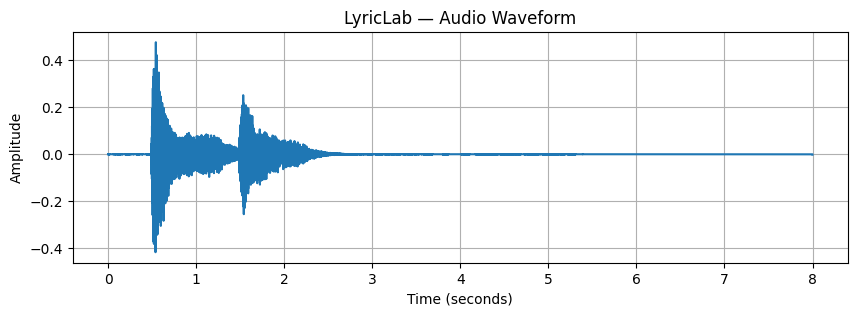

In [ ]:

audio_tensor = result.audios[0].detach().float().cpu()
audio = audio_tensor.numpy()

if audio.ndim == 2 and audio.shape[0] <= 2:
    audio = audio.T

sample_rate = 48000

sf.write("/content/LyricLab_first_song.wav", audio, sample_rate)

print("Song saved successfully!")

display(Audio(audio.T if audio.ndim == 2 else audio, rate=sample_rate))

plt.figure(figsize=(10, 3))
wave = audio if audio.ndim == 1 else audio.mean(axis=1)
plt.plot(np.arange(len(wave)) / sample_rate, wave)
plt.title("LyricLab — Audio Waveform")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()


In [ ]:

import gradio as gr
import numpy as np
import matplotlib.pyplot as plt
import soundfile as sf
import torch

def generate_song(lyrics, tone, voice, speed):
    prompt = f"{tone} music, {voice} vocals, {speed} tempo, clear singing, expressive melody"

    result = pipe(
        prompt=prompt,
        lyrics=lyrics,
        audio_duration=10.0,
        vocal_language="en",
        num_inference_steps=8,
        shift=3.0,
    )

    audio = result.audios[0].detach().float().cpu().numpy()

    if audio.ndim == 2 and audio.shape[0] <= 2:
        audio = audio.T

    sr = 48000
    song_path = "/content/LyricLab_song.wav"
    sf.write(song_path, audio, sr)

    wave = audio if audio.ndim == 1 else audio.mean(axis=1)
    fig, ax = plt.subplots(figsize=(9, 2.5))
    ax.plot(np.arange(len(wave)) / sr, wave)
    ax.set_title("Your Song's Waveform")
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Amplitude")
    ax.grid(True)
    plt.tight_layout()

    return (sr, audio), fig, song_path

with gr.Blocks(title="LyricLab AI CS3216") as app:
    gr.Markdown("# LyricLab AI 🎵")
    gr.Markdown("Turn your lyrics into music.")

    lyrics = gr.Textbox(
        label="Your lyrics",
        placeholder="Type your two lines here...",
        lines=3
    )

    with gr.Row():
        tone = gr.Dropdown(
            ["Pop", "Rap", "Classical", "Romantic", "Sad", "Upbeat", "Lo-fi"],
            value="Pop", label="Tone / Genre"
        )
        voice = gr.Radio(
            ["Male", "Female"],
            value="Female", label="Voice preference"
        )
        speed = gr.Dropdown(
            ["Slow", "Medium", "Fast"],
            value="Medium", label="Speed"
        )

    generate = gr.Button("🎵 Generate Music", variant="primary")
    player = gr.Audio(label="Your generated song")
    waveform = gr.Plot(label="Waveform curve")
    download = gr.File(label="Download your WAV")

    generate.click(
        fn=generate_song,
        inputs=[lyrics, tone, voice, speed],
        outputs=[player, waveform, download]
    )

app.launch(share=True, debug=True)


In [ ]:

import torch
from diffusers import AceStepPipeline

pipe = AceStepPipeline.from_pretrained(
    "Runware/acestep-v15-turbo-diffusers",
    dtype=torch.float16,
    low_cpu_mem_usage=True
)

pipe.enable_model_cpu_offload()
pipe.enable_attention_slicing()

print("Model restored!")


model_index.json:   0%|          | 0.00/646 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 17 files:   0%|          | 0/17 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/8 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Model restored!


In [ ]:

app.launch(share=True, debug=True)


Rerunning server... use `close()` to stop if you need to change `launch()` parameters.
----
Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://ab7aa99cf19e813143.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


KeyboardInterrupt: 

In [ ]:

import gradio as gr
import numpy as np
import matplotlib.pyplot as plt
import soundfile as sf
import torch

def generate_song(lyrics, tone, voice, speed):
    prompt = f"{tone} music, {voice} vocals, {speed} tempo, clear singing, expressive melody"

    result = pipe(
        prompt=prompt,
        lyrics=lyrics,
        audio_duration=10.0,
        vocal_language="en",
        num_inference_steps=8,
        shift=3.0,
    )

    audio = result.audios[0].detach().float().cpu().numpy()

    if audio.ndim == 2 and audio.shape[0] <= 2:
        audio = audio.T

    sr = 48000
    song_path = "/content/LyricLab_song.wav"
    sf.write(song_path, audio, sr)

    wave = audio if audio.ndim == 1 else audio.mean(axis=1)
    fig, ax = plt.subplots(figsize=(9, 2.5))
    ax.plot(np.arange(len(wave)) / sr, wave)
    ax.set_title("Your Song's Waveform")
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Amplitude")
    ax.grid(True)
    plt.tight_layout()

    return (sr, audio), fig, song_path

with gr.Blocks(title="LyricLab AI CS3216") as app:
    gr.Markdown("# LyricLab AI 🎵")
    gr.Markdown("Turn your lyrics into music.")

    lyrics = gr.Textbox(
        label="Your lyrics",
        placeholder="Type your two lines here...",
        lines=3
    )

    with gr.Row():
        tone = gr.Dropdown(
            ["Pop", "Rap", "Classical", "Romantic", "Sad", "Upbeat", "Lo-fi"],
            value="Pop", label="Tone / Genre"
        )
        voice = gr.Radio(
            ["Male", "Female"],
            value="Female", label="Voice preference"
        )
        speed = gr.Dropdown(
            ["Slow", "Medium", "Fast"],
            value="Medium", label="Speed"
        )

    generate = gr.Button("🎵 Generate Music", variant="primary")
    player = gr.Audio(label="Your generated song")
    waveform = gr.Plot(label="Waveform curve")
    download = gr.File(label="Download your WAV")

    generate.click(
        fn=generate_song,
        inputs=[lyrics, tone, voice, speed],
        outputs=[player, waveform, download]
    )

app.launch(share=True, debug=True)


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://3affeb377b0275dd82.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Guidance scale 7.0 is ignored for turbo (guidance-distilled) checkpoints.


  0%|          | 0/8 [00:00<?, ?it/s]